In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("../data/processed/german_credit_clean.csv")

df.head()

,checking_account,duration_months,credit_history,purpose,credit_amount,savings_account,employment_since,installment_rate,personal_status_sex,other_debtors,...,existing_credits,job,dependents,telephone,foreign_worker,credit_risk,bad_credit_flag,age_group,loan_duration_group,credit_amount_group
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,2,A173,1,A192,A201,Good,0,51+,<=12 months,Low
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,1,A173,1,A191,A201,Bad,1,18-25,37+ months,High
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,1,A172,2,A191,A201,Good,0,36-50,<=12 months,Low
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,1,A173,2,A191,A201,Good,0,36-50,37+ months,High
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,2,A173,2,A191,A201,Bad,1,51+,13-24 months,Medium


In [4]:
print("Shape:", df.shape)
print("-----------------------------------")

print("\nColumns:")
print(df.columns.tolist())
print("-----------------------------------")

print("\nData Types:")
print(df.dtypes)
print("-----------------------------------")


print("\nMissing Values:")
print(df.isnull().sum())
print("-----------------------------------")

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Shape: (1000, 25)
-----------------------------------

Columns:
['checking_account', 'duration_months', 'credit_history', 'purpose', 'credit_amount', 'savings_account', 'employment_since', 'installment_rate', 'personal_status_sex', 'other_debtors', 'residence_since', 'property', 'age', 'other_installment_plans', 'housing', 'existing_credits', 'job', 'dependents', 'telephone', 'foreign_worker', 'credit_risk', 'bad_credit_flag', 'age_group', 'loan_duration_group', 'credit_amount_group']
-----------------------------------

Data Types:
checking_account             str
duration_months            int64
credit_history               str
purpose                      str
credit_amount              int64
savings_account              str
employment_since             str
installment_rate           int64
personal_status_sex          str
other_debtors                str
residence_since            int64
property                     str
age                        int64
other_installment_plans      str

In [5]:
df["credit_risk"].value_counts()

credit_risk
Good    700
Bad     300
Name: count, dtype: int64

In [6]:
df["credit_risk"].value_counts(normalize=True).mul(100).round(2)

credit_risk
Good    70.0
Bad     30.0
Name: proportion, dtype: float64

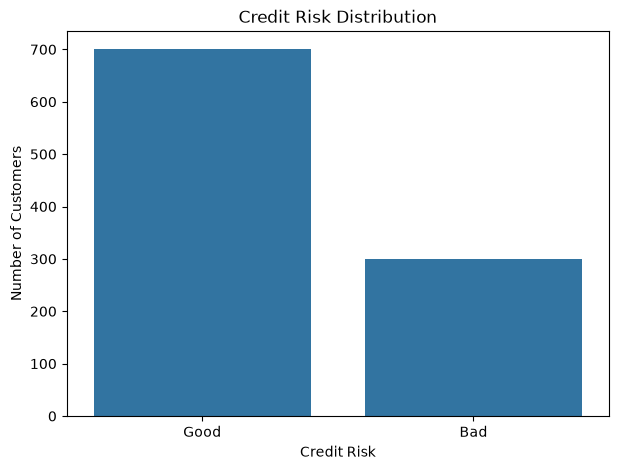

In [10]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="credit_risk"
)

plt.title("Credit Risk Distribution")
plt.xlabel("Credit Risk")
plt.ylabel("Number of Customers")

plt.show()

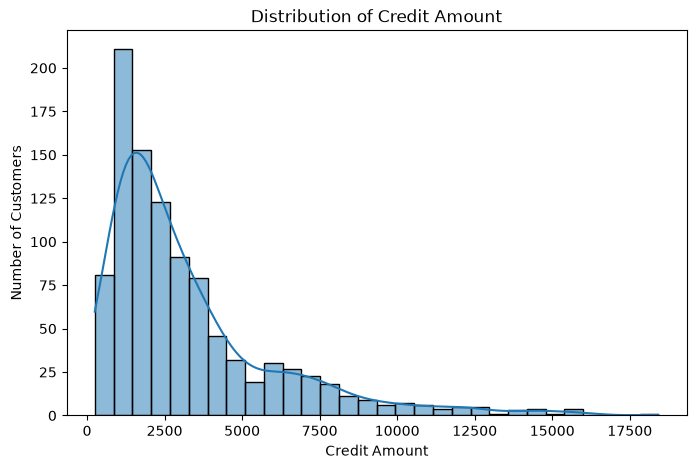

In [11]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="credit_amount",
    bins=30,
    kde=True
)

plt.title("Distribution of Credit Amount")
plt.xlabel("Credit Amount")
plt.ylabel("Number of Customers")

plt.show()

In [12]:
duration_risk = (
    df.groupby("loan_duration_group", observed=True)
      ["bad_credit_flag"]
      .mean()
      .mul(100)
      .round(2)
      .reset_index()
)

duration_risk

,loan_duration_group,bad_credit_flag
0,13-24 months,29.68
1,25-36 months,39.86
2,37+ months,51.72
3,<=12 months,21.17


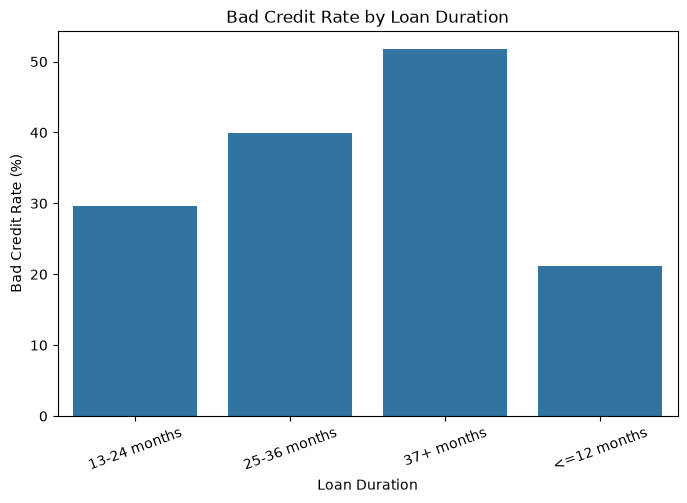

In [13]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=duration_risk,
    x="loan_duration_group",
    y="bad_credit_flag"
)

plt.title("Bad Credit Rate by Loan Duration")
plt.xlabel("Loan Duration")
plt.ylabel("Bad Credit Rate (%)")

plt.xticks(rotation=20)

plt.show()

In [14]:
history_risk = (
    df.groupby("credit_history")
      ["bad_credit_flag"]
      .mean()
      .mul(100)
      .round(2)
      .sort_values(ascending=False)
)

history_risk

credit_history
A30    62.50
A31    57.14
A32    31.89
A33    31.82
A34    17.06
Name: bad_credit_flag, dtype: float64

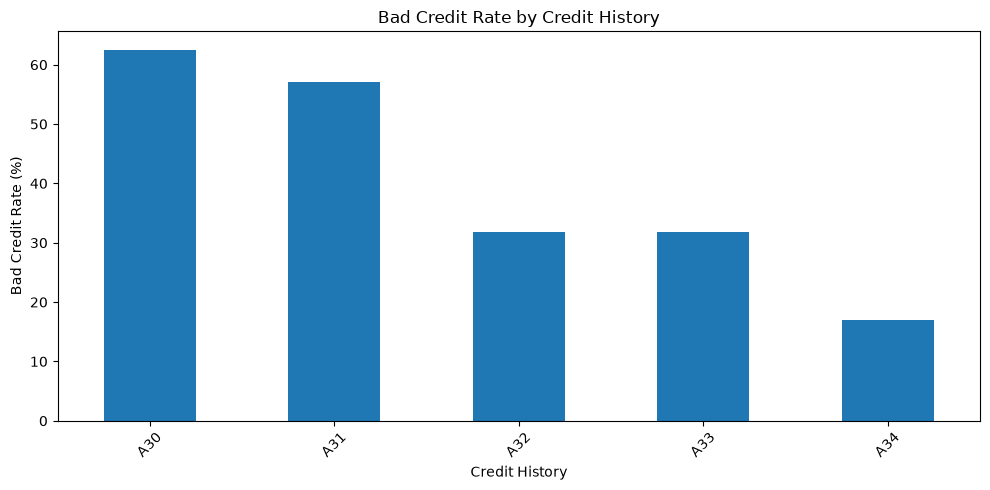

In [15]:
plt.figure(figsize=(10, 5))

history_risk.plot(kind="bar")

plt.title("Bad Credit Rate by Credit History")
plt.xlabel("Credit History")
plt.ylabel("Bad Credit Rate (%)")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [16]:
age_risk = (
    df.groupby("age_group", observed=True)
      ["bad_credit_flag"]
      .mean()
      .mul(100)
      .round(2)
      .reset_index()
)

age_risk

,age_group,bad_credit_flag
0,18-25,42.11
1,26-35,29.65
2,36-50,23.75
3,51+,27.43


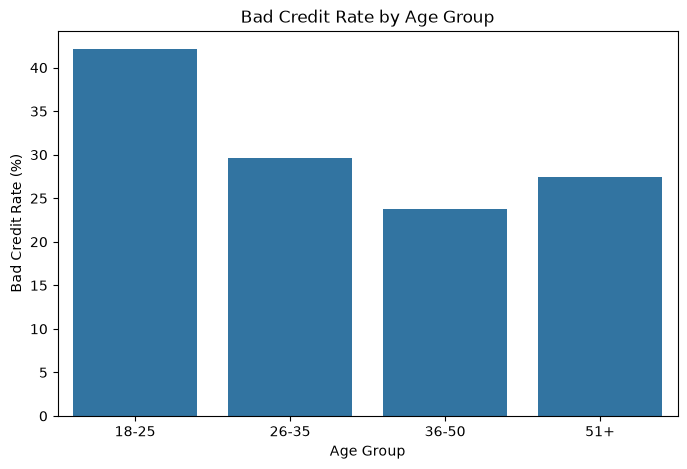

In [17]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=age_risk,
    x="age_group",
    y="bad_credit_flag"
)

plt.title("Bad Credit Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Bad Credit Rate (%)")

plt.show()

In [18]:
purpose_risk = (
    df.groupby("purpose")
      ["bad_credit_flag"]
      .mean()
      .mul(100)
      .round(2)
      .sort_values(ascending=False)
)

purpose_risk

purpose
A46     44.00
A410    41.67
A40     38.03
A45     36.36
A49     35.05
A44     33.33
A42     32.04
A43     22.14
A41     16.50
A48     11.11
Name: bad_credit_flag, dtype: float64

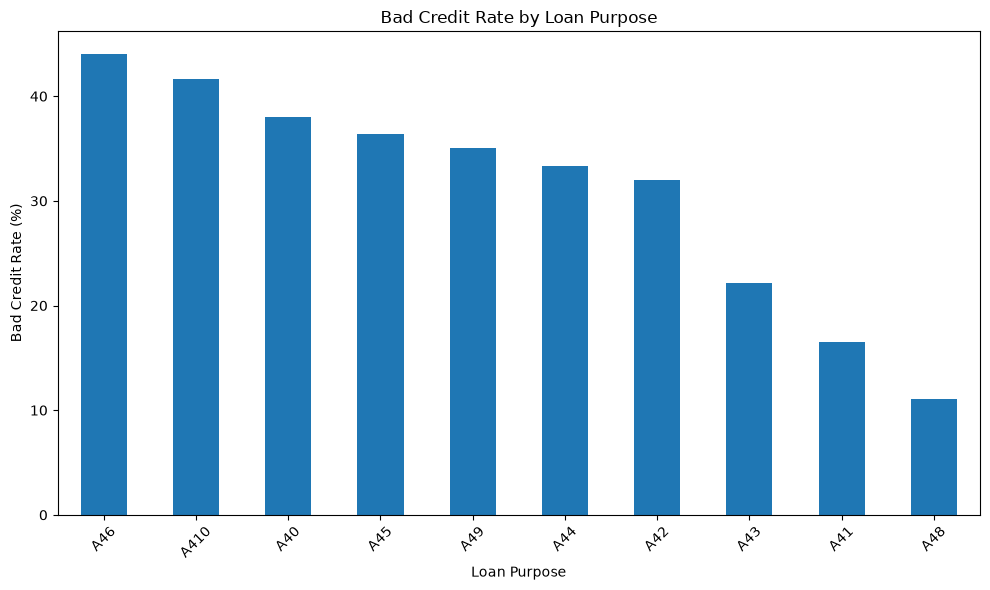

In [19]:
plt.figure(figsize=(10, 6))

purpose_risk.plot(kind="bar")

plt.title("Bad Credit Rate by Loan Purpose")
plt.xlabel("Loan Purpose")
plt.ylabel("Bad Credit Rate (%)")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [20]:
employment_risk = (
    df.groupby("employment_since")
      ["bad_credit_flag"]
      .mean()
      .mul(100)
      .round(2)
      .sort_values(ascending=False)
)

employment_risk

employment_since
A72    40.70
A71    37.10
A73    30.68
A75    25.30
A74    22.41
Name: bad_credit_flag, dtype: float64